# Distributional Evaluation of Downscaling Models

## Setup

Set `REPO_ROOT` and `CONFIG_PATH` paths according to your local repository structure.

In [1]:
from pathlib import Path
import sys

import xarray as xr

xr.set_options(
    display_expand_data=False,
    display_expand_attrs=False,
)

In [ ]:
REPO_ROOT = Path.home() / "projects" / "dl-downscaling-evaluation-ec"
CONFIG_PATH = REPO_ROOT / "config" / "config.yaml"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / "outputs" 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Data

In [ ]:
from src.io import load_config, load_dataset_series


config = load_config(CONFIG_PATH)

years = range(
    config["years"]["start"],
    config["years"]["end"] + 1
)

datasets = {
    "reference": None,
    "models": {}
}


print("\n[INFO] Loading reference dataset")

datasets["reference"] = load_dataset_series(
    config["reference"],
    years,
    lazy=False
)


print("\n[INFO] Loading model output datasets")

for model_name, cfg in config["models"].items():

    print(f"\n[INFO] Loading {model_name}")

    datasets["models"][model_name] = load_dataset_series(
        cfg,
        years,
        lazy=False
    )

### Datasets Consistency

In [4]:
from src.io import check_spatiotemporal_compatibility

reference = datasets["reference"]

for model_name, da in datasets["models"].items():

    print(f"\n[INFO] Checking {model_name}")
    check_spatiotemporal_compatibility(reference, da)


[INFO] Checking ERA5-DownGAN-EC
  time: True
  lat:  True
  lon:  True

[INFO] Checking cGAN-U-Net-EC
  time: True
  lat:  True
  lon:  True

[INFO] Checking DDIM-EC
  time: True
  lat:  True
  lon:  True


## Temperature Probability Density

In [5]:
from src.plotting import plot_temperature_distributions

PLOT_CONFIG_PATH = REPO_ROOT / "config" / "plot_config.yaml"
plot_config = load_config(PLOT_CONFIG_PATH)

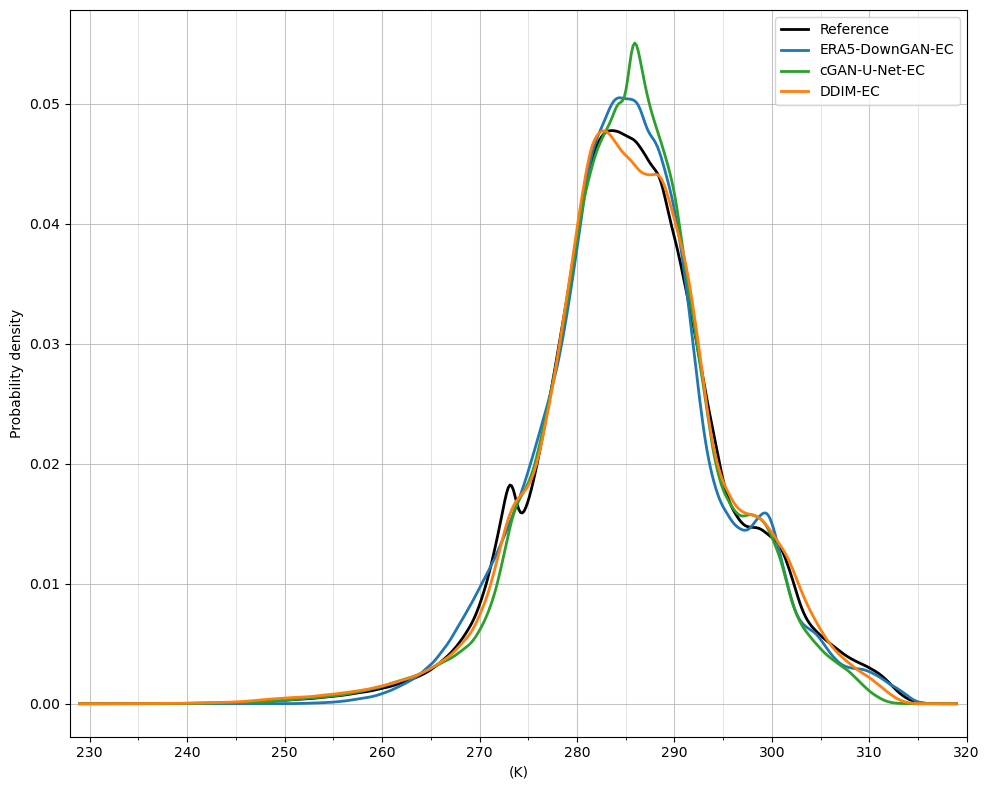

In [6]:
fig, ax = plot_temperature_distributions(
    datasets,
    n_samples=5000000,
    config=plot_config
)

In [7]:
fig.savefig(
    OUTPUT_DIR / "pdf.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "pdf.pdf",
    bbox_inches="tight"
)

## Temperature Distribution Tails

In [8]:
from src.plotting import plot_temperature_tails

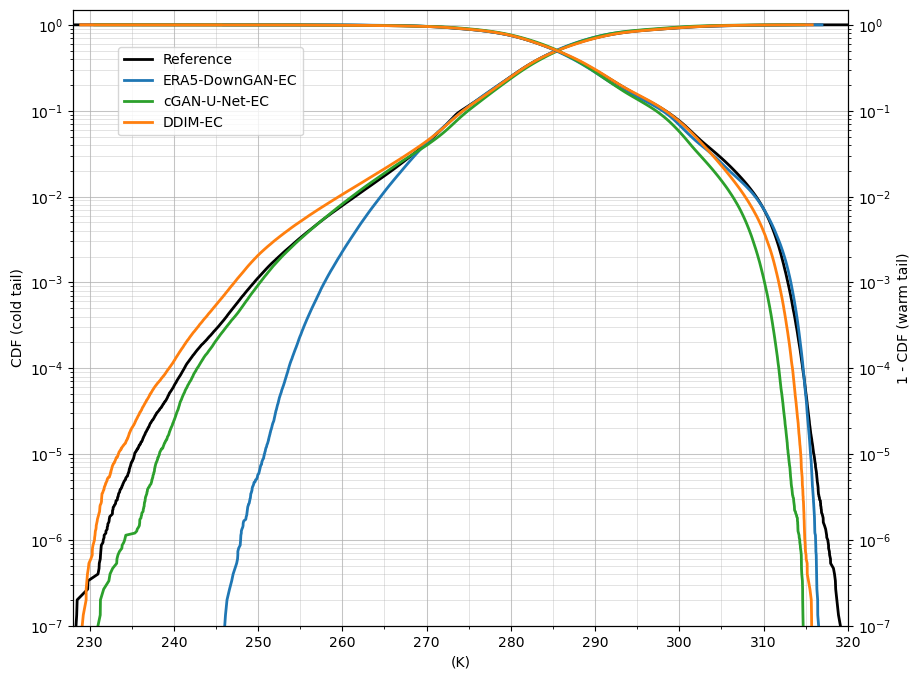

In [9]:
fig, axes = plot_temperature_tails(
    datasets,
    n_samples=15000000,
    figsize=(10, 8),
    config=plot_config
)

In [10]:
fig.savefig(
    OUTPUT_DIR / "distribution_tails.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "distribution_tails.pdf",
    bbox_inches="tight"
)

## PDF and Tail Distributions

In [11]:
from src.plotting import plot_temperature_distribution_tails

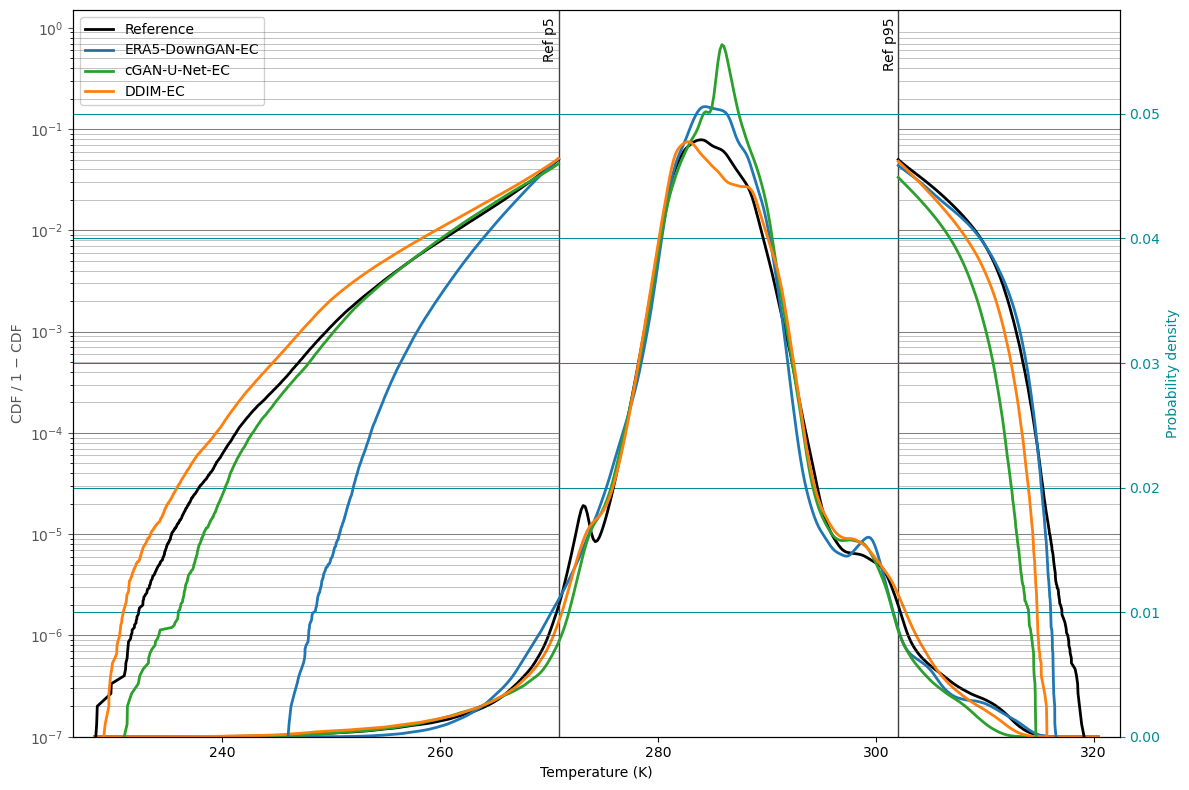

In [12]:
fig, axes = plot_temperature_distribution_tails(datasets,
                                                n_samples=15000000,
                                                figsize=(12, 8),
                                                config=plot_config
                                                )

In [13]:
fig.savefig(
    OUTPUT_DIR / "distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "distribution.pdf",
    bbox_inches="tight"
)

In [14]:
from matplotlib import pyplot as plt
from src.plotting import add_percentile_lines

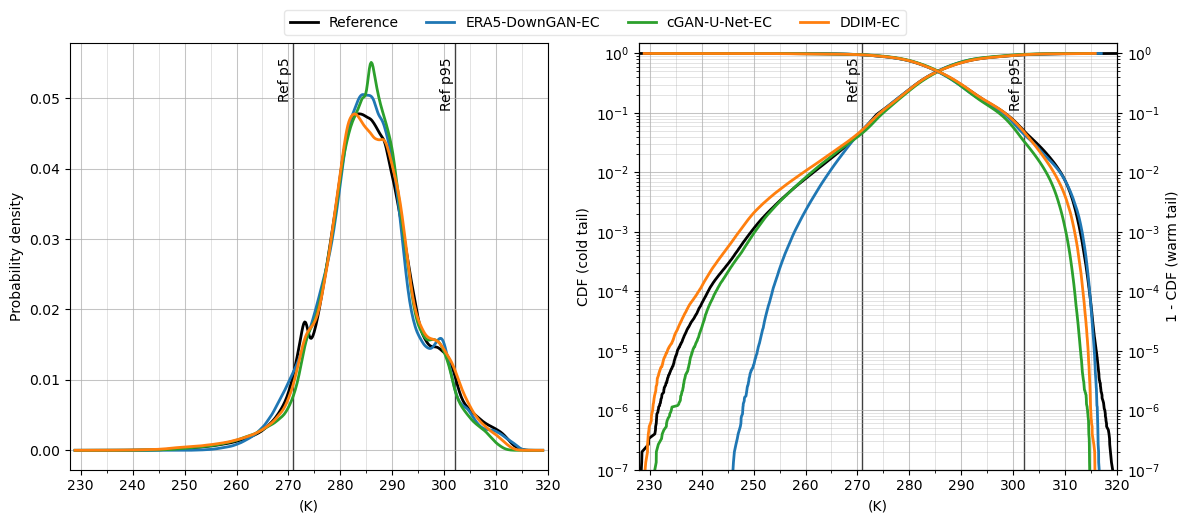

In [15]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

plot_temperature_distributions(
    datasets,
    n_samples=5000000,
    config=plot_config,
    ax=axes[0],
    show_legend=False
)

add_percentile_lines(
    axes[0],
    datasets["reference"],
    percentiles=(5, 95),
    labels=("Ref p5", "Ref p95")
)

plot_temperature_tails(
    datasets,
    n_samples=15000000,
    config=plot_config,
    ax=axes[1],
    show_legend=False
)

add_percentile_lines(
    axes[1],
    datasets["reference"],
    percentiles=(5, 95),
    labels=("Ref p5", "Ref p95")
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(labels),
    bbox_to_anchor=(0.5, 1.05),
    frameon=True,
    facecolor="white",
    framealpha=1,
    edgecolor="0.9"
)

fig.tight_layout()

In [16]:
fig.savefig(
    OUTPUT_DIR / "distribution_panel.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "distribution_panel.pdf",
    bbox_inches="tight"
)

## QQ plot

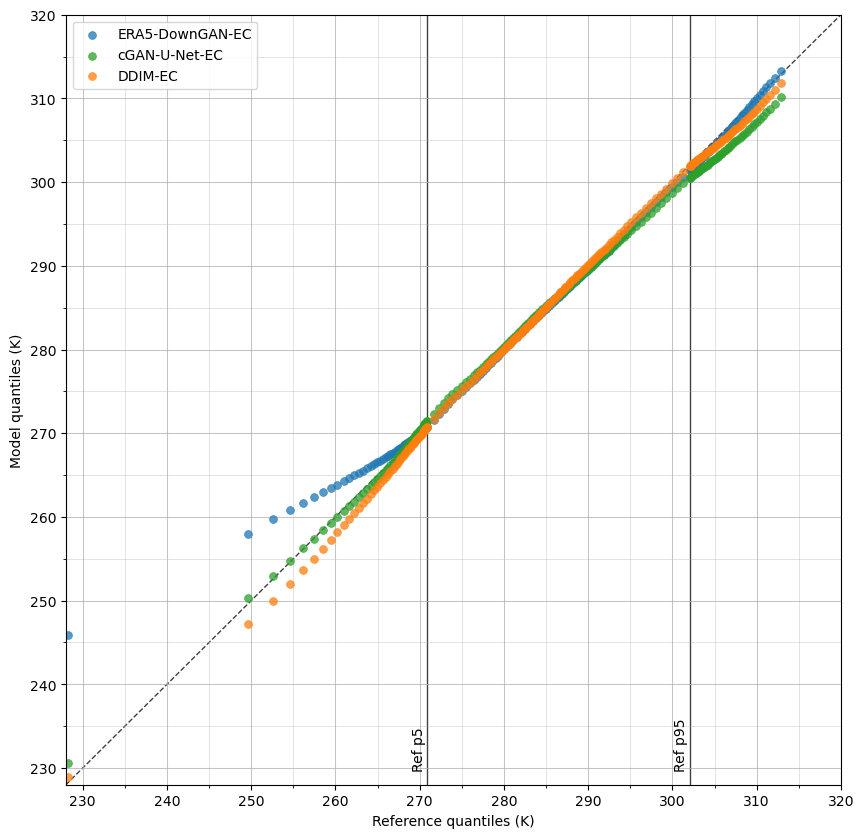

In [17]:
from src.plotting import plot_temperature_qq

fig, ax = plot_temperature_qq(
    datasets,
    n_samples=15000000,
    config=plot_config
)

In [18]:
fig.savefig(
    OUTPUT_DIR / "qq.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "qq.pdf",
    bbox_inches="tight"
)